# Red Neuronal: reconocimiento de dígitos (MNIST)

**Programa Especializado en Inteligencia Artificial** · C-DAC Noida · ITEC · India 2026  
Resuelto paso a paso — PhD (c) Luis Correa

## Clasificar dígitos escritos a mano con una red neuronal
Primero una red simple (solo entrada y salida); luego le agregamos una **capa oculta** y vemos cómo mejora.

In [1]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import numpy as np

(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

In [2]:
len(X_train)

60000

In [3]:
len(X_test)

10000

In [4]:
X_train[0].shape

(28, 28)

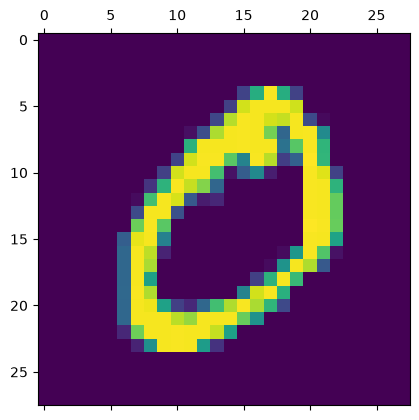

In [5]:
plt.matshow(X_train[1])
plt.show()

In [6]:
y_train[1]

np.uint8(0)

**Escalado:** pasamos los píxeles de 0–255 a 0–1.

In [7]:
X_train = X_train / 255
X_test = X_test / 255

**Aplanar:** cada imagen de 28×28 se convierte en una fila de 784 números.

In [8]:
X_train_flattened = X_train.reshape(len(X_train), 28*28)
X_test_flattened = X_test.reshape(len(X_test), 28*28)
X_train_flattened.shape

(60000, 784)

### Red neuronal muy simple (sin capa oculta)

In [9]:
model = keras.Sequential([
    keras.layers.Dense(10, input_shape=(784,), activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.fit(X_train_flattened, y_train, epochs=5)

/Users/luiscorreamatos/curso_ia_india/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5


   1/1875 ━━━━━━━━━━━━━━━━━━━━ 5:54 189ms/step - accuracy: 0.0938 - loss: 2.3243

 161/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 314us/step - accuracy: 0.6863 - loss: 1.2181  

 332/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 303us/step - accuracy: 0.7701 - loss: 0.9118

 500/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 302us/step - accuracy: 0.8072 - loss: 0.7693

... (57 outputs left out)

1413/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 284us/step - accuracy: 0.9258 - loss: 0.2705

1588/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 285us/step - accuracy: 0.9256 - loss: 0.2692

1772/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 283us/step - accuracy: 0.9259 - loss: 0.2664

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 286us/step - accuracy: 0.9255 - loss: 0.2668


In [10]:
model.evaluate(X_test_flattened, y_test)

  1/313 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - accuracy: 0.9688 - loss: 0.2860

188/313 ━━━━━━━━━━━━━━━━━━━━ 0s 267us/step - accuracy: 0.9116 - loss: 0.3183

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 278us/step - accuracy: 0.9257 - loss: 0.2692


[0.2691691219806671, 0.9257000088691711]

In [11]:
y_predicted = model.predict(X_test_flattened)
y_predicted[0]

  1/313 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step

293/313 ━━━━━━━━━━━━━━━━━━━━ 0s 171us/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 198us/step


array([1.79049633e-02, 2.73867414e-07, 4.11310159e-02, 9.61916924e-01,
       2.85967533e-03, 1.22633085e-01, 1.37717757e-06, 9.99804974e-01,
       9.47169960e-02, 6.77057981e-01], dtype=float32)

`np.argmax` toma el elemento mayor y devuelve su índice (el dígito predicho).

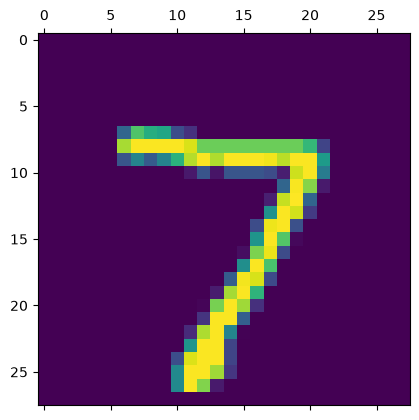

np.int64(7)

In [12]:
plt.matshow(X_test[0])
plt.show()
np.argmax(y_predicted[0])

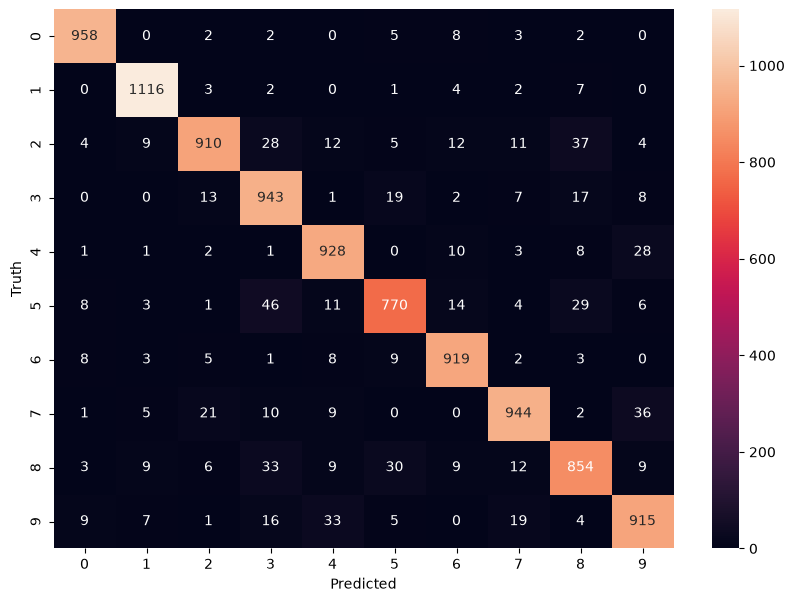

In [13]:
import seaborn as sn
y_predicted_labels = [np.argmax(i) for i in y_predicted]
cm = tf.math.confusion_matrix(labels=y_test, predictions=y_predicted_labels)
plt.figure(figsize=(10,7))
sn.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Truth')
plt.show()

### Usando una capa oculta (100 neuronas ReLU)

In [14]:
model = keras.Sequential([
    keras.layers.Dense(100, input_shape=(784,), activation='relu'),
    keras.layers.Dense(10, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.fit(X_train_flattened, y_train, epochs=5)

/Users/luiscorreamatos/curso_ia_india/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5


   1/1875 ━━━━━━━━━━━━━━━━━━━━ 7:07 228ms/step - accuracy: 0.0625 - loss: 2.5723

  80/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 637us/step - accuracy: 0.6922 - loss: 1.1568  

 173/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 584us/step - accuracy: 0.7887 - loss: 0.7738

 261/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 579us/step - accuracy: 0.8289 - loss: 0.6229

... (104 outputs left out)

1669/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 513us/step - accuracy: 0.9844 - loss: 0.0515

1767/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 513us/step - accuracy: 0.9844 - loss: 0.0512

1865/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 513us/step - accuracy: 0.9846 - loss: 0.0507

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 516us/step - accuracy: 0.9847 - loss: 0.0506


In [15]:
model.evaluate(X_test_flattened, y_test)

  1/313 ━━━━━━━━━━━━━━━━━━━━ 13s 43ms/step - accuracy: 0.9688 - loss: 0.0853

159/313 ━━━━━━━━━━━━━━━━━━━━ 0s 318us/step - accuracy: 0.9646 - loss: 0.1138

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 324us/step - accuracy: 0.9741 - loss: 0.0824


[0.08240412175655365, 0.9740999937057495]

  1/313 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step

247/313 ━━━━━━━━━━━━━━━━━━━━ 0s 204us/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 245us/step


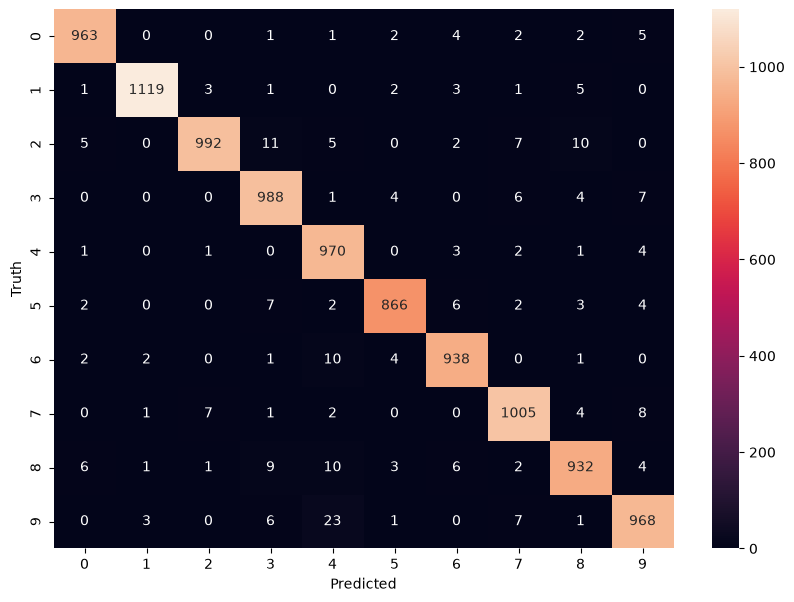

In [16]:
y_predicted = model.predict(X_test_flattened)
y_predicted_labels = [np.argmax(i) for i in y_predicted]
cm = tf.math.confusion_matrix(labels=y_test, predictions=y_predicted_labels)
plt.figure(figsize=(10,7))
sn.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Truth')
plt.show()

### Usando la capa Flatten (para no tener que hacer reshape a mano)

In [17]:
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(100, activation='relu'),
    keras.layers.Dense(10, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.fit(X_train, y_train, epochs=10)

/Users/luiscorreamatos/curso_ia_india/.venv/lib/python3.12/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10


   1/1875 ━━━━━━━━━━━━━━━━━━━━ 9:51 316ms/step - accuracy: 0.0000e+00 - loss: 2.4997

  93/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 544us/step - accuracy: 0.7241 - loss: 1.0283      

 188/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 537us/step - accuracy: 0.8059 - loss: 0.7171

 282/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 536us/step - accuracy: 0.8374 - loss: 0.5972

... (210 outputs left out)

1610/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 531us/step - accuracy: 0.9947 - loss: 0.0176

1705/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 531us/step - accuracy: 0.9946 - loss: 0.0181

1801/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 531us/step - accuracy: 0.9945 - loss: 0.0185

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 534us/step - accuracy: 0.9944 - loss: 0.0185


In [18]:
model.evaluate(X_test, y_test)

  1/313 ━━━━━━━━━━━━━━━━━━━━ 16s 52ms/step - accuracy: 1.0000 - loss: 0.0153

156/313 ━━━━━━━━━━━━━━━━━━━━ 0s 323us/step - accuracy: 0.9690 - loss: 0.1073

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 327us/step - accuracy: 0.9777 - loss: 0.0775


[0.07748249918222427, 0.9776999950408936]